# Example 9.2 — Complete GA for Trajectory Synthesis

**Chapter 9: Step-by-Step Trajectory Synthesis**

It implements the genetic algorithm with BLX-0.3 crossover, Gaussian mutation, Grashof constraints, and transmission angle.

## 1. GA parameters and target trajectory

In [7]:
from numpy import *
from numpy import random

N_GEN, N_POP = 300, 80
PC, PM = 0.85, 0.04
N_PUNTOS = 20

LB = array([20, 20, 20, 20, -80, -80, 0])
UB = array([150, 150, 150, 150, 80, 80, 360])

def trayectoria_gota(n=N_PUNTOS):
    t = linspace(0, 2 * pi, n, endpoint=False)
    f = 1 - 0.5 * sin(t / 2)
    return 100 + 50 * cos(t) * f, 100 + 50 * sin(t) * f

print(f'GA: {N_GEN} generations, population {N_POP}')
print(f'Variables: r1, r2, r3, r4 ∈ [20, 150] mm')
print(f'           xp, yp ∈ [-80, 80] mm')
print(f'           θ₂₀ ∈ [0°, 360°]')

GA: 300 generations, population 80
Variables: r1, r2, r3, r4 ∈ [20, 150] mm
           xp, yp ∈ [-80, 80] mm
           θ₂₀ ∈ [0°, 360°]


## 2. Analysis and fitness functions

In [8]:
import builtins

def analizar(r1, r2, r3, r4, t2):
    A = 2 * r4 * (r1 - r2 * cos(t2))
    B = -2 * r2 * r4 * sin(t2)
    C = r1**2 + r2**2 + r4**2 - r3**2 - 2 * r1 * r2 * cos(t2)
    d = A**2 + B**2 - C**2
    if d < 0:
        return None, None
    t4 = 2 * arctan2(-B + sqrt(d), A - C)
    t3 = arctan2((r4 * sin(t4) - r2 * sin(t2)) / r3,
                 (r1 + r4 * cos(t4) - r2 * cos(t2)) / r3)
    return t3, t4

def aptitud(ind, xd, yd):
    r1, r2, r3, r4, xp, yp, t20 = ind
    s, l = builtins.min(r1, r2, r3, r4), builtins.max(r1, r2, r3, r4)
    if s + l >= (r1 + r2 + r3 + r4 - s - l):
        return 1e6
    t2s = linspace(radians(t20), radians(t20) + 2 * pi, N_PUNTOS, endpoint=False)
    E = 0.0
    for i, t2 in enumerate(t2s):
        t3, t4 = analizar(r1, r2, r3, r4, t2)
        if t3 is None:
            return 1e6
        mu = degrees(abs(t3 - t4)) % 180
        if mu > 90:
            mu = 180 - mu
        if mu < 40:
            E += (40 - mu) * 50
        xa = r2 * cos(t2) + xp * cos(t3) - yp * sin(t3)
        ya = r2 * sin(t2) + xp * sin(t3) + yp * cos(t3)
        E += sqrt((xa - xd[i])**2 + (ya - yd[i])**2)
    return E

## 3. GA main loop

In [9]:
from numpy import *
from numpy import random
import builtins

def analizar(r1, r2, r3, r4, t2):
    A = 2 * r4 * (r1 - r2 * cos(t2))
    B = -2 * r2 * r4 * sin(t2)
    C = r1**2 + r2**2 + r4**2 - r3**2 - 2 * r1 * r2 * cos(t2)
    d = A**2 + B**2 - C**2
    if d < 0:
        return None, None
    t4 = 2 * arctan2(-B + sqrt(d), A - C)
    t3 = arctan2((r4 * sin(t4) - r2 * sin(t2)) / r3,
                 (r1 + r4 * cos(t4) - r2 * cos(t2)) / r3)
    return t3, t4

def aptitud(ind, xd, yd):
    r1, r2, r3, r4, xp, yp, t20 = ind
    s, l = builtins.min(r1, r2, r3, r4), builtins.max(r1, r2, r3, r4)
    if s + l >= (r1 + r2 + r3 + r4 - s - l):
        return 1e6
    t2s = linspace(radians(t20), radians(t20) + 2 * pi, N_PUNTOS, endpoint=False)
    E = 0.0
    for i, t2 in enumerate(t2s):
        t3, t4 = analizar(r1, r2, r3, r4, t2)
        if t3 is None:
            return 1e6
        mu = degrees(abs(t3 - t4)) % 180
        if mu > 90:
            mu = 180 - mu
        if mu < 40:
            E += (40 - mu) * 50
        xa = r2 * cos(t2) + xp * cos(t3) - yp * sin(t3)
        ya = r2 * sin(t2) + xp * sin(t3) + yp * cos(t3)
        E += sqrt((xa - xd[i])**2 + (ya - yd[i])**2)
    return E

random.seed(42)
xd, yd = trayectoria_gota()
pop = random.uniform(0, 1, (N_POP, 7)) * (UB - LB) + LB
fit = array([aptitud(p, xd, yd) for p in pop])
historia = [min(fit)]

for gen in range(N_GEN):
    # Tournament selection of two
    idx = random.randint(0, N_POP, (N_POP, 2))
    nueva = array([pop[i1] if fit[i1] < fit[i2] else pop[i2] for i1, i2 in idx])

    # Crossing BLX-0.3
    for i in range(0, N_POP - 1, 2):
        if random.rand() < PC:
            d = abs(nueva[i] - nueva[i + 1])
            lo = minimum(nueva[i], nueva[i + 1]) - 0.3 * d
            hi = maximum(nueva[i], nueva[i + 1]) + 0.3 * d
            nueva[i] = clip(lo + random.rand(7) * (hi - lo), LB, UB)
            nueva[i + 1] = clip(lo + random.rand(7) * (hi - lo), LB, UB)

    # Gaussian mutation
    nueva += (random.rand(N_POP, 7) < PM) * random.randn(N_POP, 7) * (UB - LB) * 0.05
    nueva = clip(nueva, LB, UB)
    nueva_fit = array([aptitud(p, xd, yd) for p in nueva])

    # Elitism
    nueva[0] = pop[argmin(fit)]
    nueva_fit[0] = fit[argmin(fit)]
    pop, fit = nueva, nueva_fit
    historia.append(min(fit))

    if (gen + 1) % 50 == 0:
        print(f'Gen {gen + 1:>3}: best = {min(fit):.2f} mm')

mejor = pop[argmin(fit)]
print(f'\nGenerations: {N_GEN}  |  Population: {N_POP}')
print(f'Best final error: {min(fit):.4f} mm')
print(f'Design: r1={mejor[0]:.2f}, r2={mejor[1]:.2f}, r3={mejor[2]:.2f}, r4={mejor[3]:.2f} mm')
print(f'Coupler: xp={mejor[4]:.2f}, yp={mejor[5]:.2f} mm')
print(f'Initial angle: θ₂₀={mejor[6]:.2f}°')

Gen  50: best = 952.81 mm
Gen 100: best = 702.42 mm
Gen 150: best = 702.07 mm
Gen 200: best = 699.88 mm
Gen 250: best = 698.47 mm
Gen 300: best = 698.18 mm

Generations: 300  |  Population: 80
Best final error: 698.1826 mm
Design: r1=119.04, r2=20.00, r3=100.54, r4=150.00 mm
Coupler: xp=80.00, yp=-80.00 mm
Initial angle: θ₂₀=296.24°


## 4. Convergence curve

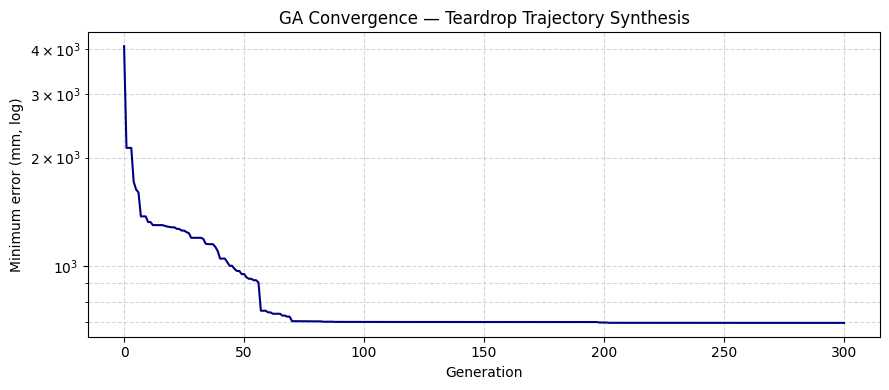

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.semilogy(historia, color='navy')
plt.xlabel('Generation')
plt.ylabel('Minimum error (mm, log)')
plt.title('GA Convergence — Teardrop Trajectory Synthesis')
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('convergencia_ag.png', dpi=150, bbox_inches='tight')
plt.show()